# Le simple placé, pour le gain

## La question

Le document précédent misait 1 € au **simple gagnant**, et prenait la cote au départ comme
prix encaissé. Ici le pari change : **1 € au e-simple placé**. Le cheval n'a plus besoin de
gagner. Il doit finir dans les places que le PMU paie — deux chevaux si la course est courte,
trois le plus souvent. L'argent rendu n'est plus la cote : c'est le **dividende définitif**
du rapport, celui qui est connu une fois l'arrivée arrêtée.

La question reste la même. On ne cherche pas le cheval qui se place le plus souvent. On
cherche la règle qui **rend le plus d'euros**. Un outsider au gagnant peut être une affaire
au placé, parce que le prix est plus court et que la réussite est plus fréquente. Il peut
aussi rester un mauvais achat, si le public le joue déjà trop.

Ce n'est pas un système de jeu. La mise est d'1 €, à plat. La période est la même : du
**1er janvier 2025 au 31 août 2026**. On apprend sur le premier semestre 2025, on recale les
chances de juillet à décembre 2025, et on juge sur **2026**, jusqu'au 31 août.

Le dividende du placé n'existe pas avant l'arrivée. Pour choisir le cheval, on n'a que ce
qui est connu avant le départ, en particulier la cote du gagnant. Le rapport ne sert qu'à
compter l'argent, ensuite.


## Sommaire

1. [Ce que paie le rapport](#rapport)
2. [Ce que rapporte chaque prix du gagnant](#prix)
3. [Favori, deuxième prix, outsider](#regles)
4. [Choisir l'espérance plutôt que la place](#esperance)
5. [Passer son tour quand le prix n'est pas là](#passer)
6. [Ce qu'il ne faut pas conclure trop vite](#limites)
7. [Verdict](#verdict)


In [1]:
import sys
import warnings
from pathlib import Path

project_root = Path.cwd()
if not (project_root / "pmu").exists():
    project_root = project_root.parent
sys.path.append(str(project_root))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

import design_system as ds
from dataset.load_jeu_modelisation import load_jeu_modelisation
from dataset.utils import DATE_WINDOW, load_sql
from pmu.types.types import ProgrammeIdentifier
from pmu.utils import programme_date_to_date

warnings.filterwarnings("ignore", category=FutureWarning)
THEME = ds.apply_theme("light")

start_date = ProgrammeIdentifier("01012025")
end_date = ProgrammeIdentifier("31082026")
debut = pd.Timestamp(programme_date_to_date(str(start_date)))
fin = pd.Timestamp(programme_date_to_date(str(end_date)))


In [2]:
ESPACE = "\u202f"


def nombre(valeur, decimales=0, unite=""):
    if pd.isna(valeur):
        return "—"
    texte = f"{valeur:,.{decimales}f}".replace(",", ESPACE).replace(".", ",")
    return f"{texte}{unite}"


def tableau(frame, titre=None, formats=None):
    styler = frame.style.set_table_styles(ds.table_css("light"))
    if titre:
        styler = styler.set_caption(titre)
    if formats:
        styler = styler.format(formats, na_rep="—")
    else:
        styler = styler.format(thousands=ESPACE, decimal=",", na_rep="—")
    return styler


def chiffres_cles(valeurs: dict, titre: str):
    frame = pd.DataFrame({"": list(valeurs.values())}, index=list(valeurs.keys()))
    return tableau(frame, titre, formats={"": "{}"})


def figure(titre: str, figsize=(11, 4.4)):
    fig, ax = plt.subplots(figsize=figsize)
    ax.set_title(titre)
    return fig, ax


def une_mise(frame, score, croissant=False):
    ordre = frame.assign(_score=np.asarray(score)).sort_values("_score", ascending=croissant)
    return ordre.groupby("course_id", observed=True).head(1)


def decrire(choix, nom, courses):
    pay = choix["retour"].to_numpy(dtype=float)
    n = len(pay)
    if n == 0:
        return {
            "Règle": nom,
            "Paris": 0,
            "Courses jouées": 0.0,
            "Chevaux payés": np.nan,
            "Euros rendus pour 1 €": np.nan,
            "Marge de hasard (±)": np.nan,
            "Cote gagnant médiane": np.nan,
            "Rang de prix médian": np.nan,
        }
    se = pay.std(ddof=1) / np.sqrt(n) if n > 1 else np.nan
    return {
        "Règle": nom,
        "Paris": n,
        "Courses jouées": n / courses,
        "Chevaux payés": float(choix["place_paye"].mean()),
        "Euros rendus pour 1 €": float(pay.mean()),
        "Marge de hasard (±)": float(2 * se),
        "Cote gagnant médiane": float(choix["cote_utile"].median()),
        "Rang de prix médian": float(choix["rang_prix"].median()),
    }


FORMATS_REGLES = {
    "Paris": lambda v: nombre(v),
    "Courses jouées": lambda v: nombre(v * 100, 1, " %"),
    "Chevaux payés": lambda v: nombre(v * 100, 1, " %"),
    "Euros rendus pour 1 €": lambda v: nombre(v, 3, " €"),
    "Marge de hasard (±)": lambda v: nombre(v, 3, " €"),
    "Cote gagnant médiane": lambda v: nombre(v, 1),
    "Rang de prix médian": lambda v: nombre(v, 1),
}


<a id="rapport"></a>
## 1. Ce que paie le rapport

Le rapport du e-simple placé donne, pour chaque cheval payé, un dividende. Dans la base ce
dividende est en **centimes pour une mise d'1 €** : 190 veut dire 1,90 € rendus. Un cheval
absent du rapport n'a rien touché : la mise est perdue.

On ne confond pas « dans les trois premiers » et « payé ». Sur une course de quatre à sept
partants, le PMU ne paie que deux places. Le troisième a bien fini devant, et le rapport ne
lui verse rien.

La cote utilisée pour classer les chevaux avant le départ est celle du **simple gagnant**.
Ce n'est pas le prix du placé. Elle sert seulement à dire qui est le favori et qui est
l'outsider au moment du pari.


In [3]:
DIVIDENDES_PLACE = f'''
select
    course_id,
    (ligne.valeur -> 'combinaison' ->> 0)::int as num_pmu,
    (ligne.valeur ->> 'dividendePourUnEuro')::float / 100.0 as dividende_euro,
    coalesce((raw ->> 'rembourse')::boolean, false) as rembourse
from rapport
cross join lateral json_array_elements(raw -> 'rapports') as ligne(valeur)
where {DATE_WINDOW}
    and raw ->> 'typePari' = 'E_SIMPLE_PLACE'
    and (ligne.valeur -> 'combinaison' ->> 0) ~ '^[0-9]+$'
'''

rapports = load_sql(DIVIDENDES_PLACE, start_date, end_date)
rapports = rapports.loc[~rapports["rembourse"]].copy()
rapports = (
    rapports.groupby(["course_id", "num_pmu"], as_index=False)["dividende_euro"].max()
)

brut = load_jeu_modelisation(start_date, end_date)
brut["gains_euros"] = brut["gains_carriere"] / 100
brut["taux_victoire"] = np.where(
    brut["nombre_courses"] > 0, brut["nombre_victoires"] / brut["nombre_courses"], np.nan
)
brut["taux_place"] = np.where(
    brut["nombre_courses"] > 0, brut["nombre_places"] / brut["nombre_courses"], np.nan
)
brut["log_gains"] = np.log10(brut["gains_euros"].clip(lower=1))
brut["cote_utile"] = brut["cote_directe"].where(brut["cote_directe"].between(1, 998))
brut["log_cote"] = np.log(brut["cote_utile"])
brut["dans_les_trois"] = brut["ordre_arrivee"].between(1, 3)

courses_rapport = rapports["course_id"].unique()
jeu = brut[brut["course_id"].isin(courses_rapport)].copy()
jeu = jeu.merge(rapports, on=["course_id", "num_pmu"], how="left")
jeu["place_paye"] = jeu["dividende_euro"].notna()
jeu["retour"] = jeu["dividende_euro"].fillna(0.0)

prix = jeu.dropna(
    subset=["cote_utile", "taux_victoire", "taux_place", "age", "nombre_partants", "log_gains"]
).copy()
courses_ok = prix.loc[prix["place_paye"], "course_id"].unique()
prix = prix[prix["course_id"].isin(courses_ok)].copy()
prix["place_corde_connue"] = prix["place_corde"].notna().astype(float)
prix["place_corde"] = prix["place_corde"].fillna(prix["nombre_partants"] / 2)
prix["log_partants"] = np.log(prix["nombre_partants"].clip(lower=1))
prix["rang_prix"] = prix.groupby("course_id")["cote_utile"].rank(method="first", ascending=True)

places_par_course = prix.groupby("course_id")["place_paye"].sum()
dans_les_trois = prix["dans_les_trois"]
premier = pd.to_datetime(prix["date_programme"]).min()
dernier = pd.to_datetime(prix["date_programme"]).max()
display(
    chiffres_cles(
        {
            "Période": f"{debut:%d/%m/%Y} → {fin:%d/%m/%Y}",
            "Première course utilisable": f"{premier:%d/%m/%Y}",
            "Dernière course utilisable": f"{dernier:%d/%m/%Y}",
            "Journées distinctes": nombre(pd.to_datetime(prix["date_programme"]).dt.normalize().nunique()),
            "Courses avec un rapport placé": nombre(prix["course_id"].nunique()),
            "Partants avec une cote": nombre(len(prix)),
            "Partants payés par le rapport": f"{nombre(prix['place_paye'].mean() * 100, 1)} %",
            "Dividende médian quand le cheval est payé": nombre(prix.loc[prix["place_paye"], "dividende_euro"].median(), 2, " €"),
            "Courses qui paient 2 places": nombre((places_par_course == 2).sum()),
            "Courses qui paient 3 places": nombre((places_par_course == 3).sum()),
            "Dans les trois premiers, mais non payés": f"{nombre((dans_les_trois & ~prix['place_paye']).sum() / dans_les_trois.sum() * 100, 1)} %",
        },
        "Le simple placé, tel que le rapport le solde",
    )
)


,
Période,01/01/2025 → 31/08/2026
Première course utilisable,01/01/2025
Dernière course utilisable,31/08/2026
Journées distinctes,608
Courses avec un rapport placé,26 921
Partants avec une cote,283 835
Partants payés par le rapport,"26,4 %"
Dividende médian quand le cheval est payé,"2,20 €"
Courses qui paient 2 places,4 090
Courses qui paient 3 places,21 889


**À retenir.** Du 1er janvier 2025 au 31 août 2026, 26 921 courses ont un rapport de simple
placé exploitable. Un partant sur quatre est payé (26 %), et quand il l'est le dividende
médian est de 2,20 €. La plupart des courses paient trois chevaux (21 889), un plus petit
nombre n'en paie que deux (4 090). Finir dans les trois premiers ne suffit pas : 3,5 % de
ces chevaux ne touchent rien. **C'est le rapport qui solde la mise, pas la place à
l'arrivée.**


<a id="prix"></a>
## 2. Ce que rapporte chaque prix du gagnant

On ne connaît pas, avant le départ, le dividende du placé. On connaît la cote du gagnant.
La question est donc : **si l'on joue au placé tous les chevaux d'une même tranche de cote
gagnant, combien rend 1 € ?** Chaque partant est une mise. S'il est dans le rapport, on
encaisse son dividende. Sinon, on encaisse 0.


,Partants,Part de chevaux payés,Dividende médian si payé,Euros rendus pour 1 €
tranche,,,,
1 à 2,4 146,"78,2 %","1,20 €","0,958 €"
"2 à 3,5",17 298,"63,6 %","1,40 €","0,938 €"
"3,5 à 6",33 757,"49,2 %","1,80 €","0,909 €"
6 à 10,44 995,"36,8 %","2,30 €","0,893 €"
10 à 18,55 452,"25,3 %","3,30 €","0,868 €"
18 à 40,63 479,"15,3 %","5,00 €","0,820 €"
40 et plus,64 708,"5,9 %","9,70 €","0,632 €"


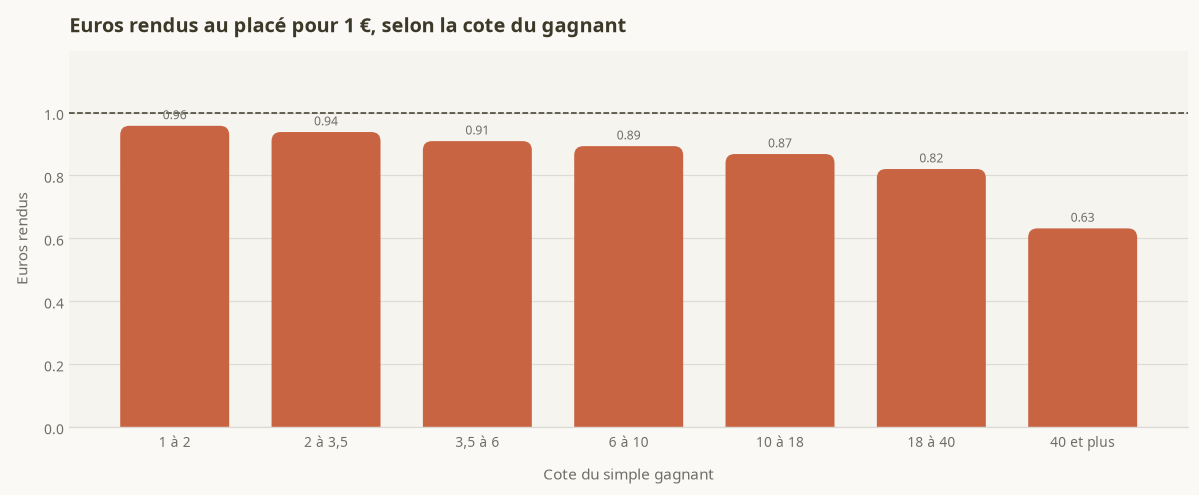

In [4]:
bornes = [1, 2, 3.5, 6, 10, 18, 40, 1000]
etiquettes = ["1 à 2", "2 à 3,5", "3,5 à 6", "6 à 10", "10 à 18", "18 à 40", "40 et plus"]
prix["tranche"] = pd.cut(prix["cote_utile"], bornes, right=False, labels=etiquettes)

par_prix = prix.groupby("tranche", observed=True).agg(
    partants=("cote_utile", "size"),
    payes=("place_paye", "mean"),
    dividende=("dividende_euro", "median"),
    euros=("retour", "mean"),
)
par_prix = par_prix.rename(
    columns={
        "partants": "Partants",
        "payes": "Part de chevaux payés",
        "dividende": "Dividende médian si payé",
        "euros": "Euros rendus pour 1 €",
    }
)

display(
    tableau(
        par_prix,
        "Un euro au placé sur chaque partant, selon la cote du gagnant",
        formats={
            "Partants": lambda v: nombre(v),
            "Part de chevaux payés": lambda v: nombre(v * 100, 1, " %"),
            "Dividende médian si payé": lambda v: nombre(v, 2, " €"),
            "Euros rendus pour 1 €": lambda v: nombre(v, 3, " €"),
        },
    )
)

fig, ax = figure("Euros rendus au placé pour 1 €, selon la cote du gagnant", (11, 4.6))
valeurs = par_prix["Euros rendus pour 1 €"]
ax.bar(valeurs.index.astype(str), valeurs.to_numpy(), color=THEME["primary"], width=0.72)
ax.axhline(1, color=THEME["foreground"], linewidth=1, linestyle="--")
ds.annotate_bars(ax, fmt="{:.2f}")
ds.rounded_bars(ax)
ax.set_ylabel("Euros rendus")
ax.set_xlabel("Cote du simple gagnant")
ax.set_ylim(0, max(1.15, float(valeurs.max()) * 1.25))
fig.tight_layout()


**À retenir.** Aucune tranche de cote gagnant ne rend 1 € au placé. Le grand favori est le
moins mauvais achat : 78 % des chevaux à moins de 2 sont payés, pour un dividende médian de
1,20 €, et 1 € misé en rend 0,96. Plus la cote du gagnant s'allonge, plus le dividende du
placé monte — jusqu'à 9,70 € au-delà de 40 — et plus le rendement baisse, jusqu'à 0,63 €.
Le prix plus généreux ne compense pas la rareté. **Jouer un outsider au placé parce que son
dividende est plus long reste le plus mauvais achat.**


<a id="regles"></a>
## 3. Favori, deuxième prix, outsider

On joue **un seul cheval par course**, choisi d'après la cote du gagnant. Le rang 1 est le
favori. « Le plus gros outsider » est le cheval à la cote gagnant la plus haute. Le rapport
du placé dit ensuite combien cette mise a rendu.

La marge de hasard indique de combien le résultat pourrait encore bouger pour cette seule
raison. Elle est plus étroite qu'au gagnant : on est payé plus souvent, et les dividendes
sont plus courts.


,Paris,Courses jouées,Chevaux payés,Euros rendus pour 1 €,Marge de hasard (±),Cote gagnant médiane,Rang de prix médian
Règle,,,,,,,
Rang 1 dans les prix,26 921,"100,0 %","61,8 %","0,944 €","0,010 €","2,9","1,0"
Rang 2 dans les prix,26 813,"99,6 %","48,4 %","0,908 €","0,013 €","4,8","2,0"
Rang 3 dans les prix,26 658,"99,0 %","39,9 %","0,883 €","0,014 €","6,9","3,0"
Rang 4 dans les prix,26 425,"98,2 %","32,4 %","0,863 €","0,017 €","9,2","4,0"
Rang 5 dans les prix,25 961,"96,4 %","26,8 %","0,852 €","0,019 €","12,0","5,0"
Rang 6 dans les prix,25 058,"93,1 %","21,6 %","0,813 €","0,021 €","15,0","6,0"
Le plus gros outsider,26 921,"100,0 %","7,2 %","0,596 €","0,033 €","72,0","10,0"


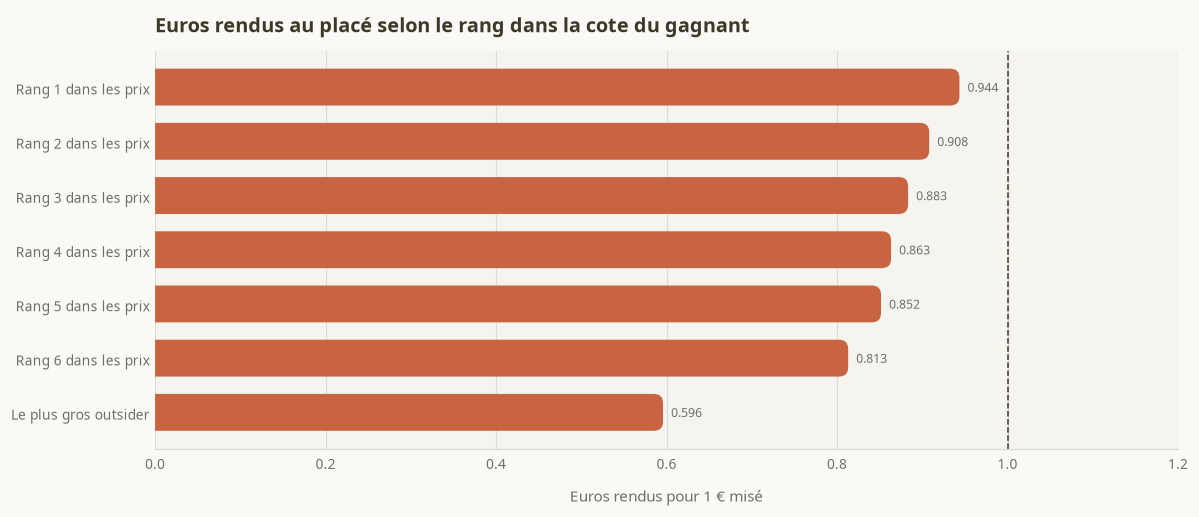

In [5]:
courses = prix["course_id"].nunique()
regles_prix = [
    decrire(prix[prix["rang_prix"] == rang], f"Rang {rang} dans les prix", courses) for rang in range(1, 7)
]
outsider = prix.loc[prix.groupby("course_id")["rang_prix"].transform("max") == prix["rang_prix"]]
regles_prix.append(decrire(outsider, "Le plus gros outsider", courses))
bilan_prix = pd.DataFrame(regles_prix).set_index("Règle")
display(
    tableau(
        bilan_prix,
        "Une mise d'1 € au placé par course, le cheval choisi d'après la cote du gagnant",
        formats=FORMATS_REGLES,
    )
)

fig, ax = figure("Euros rendus au placé selon le rang dans la cote du gagnant", (11, 4.8))
serie = bilan_prix["Euros rendus pour 1 €"]
ax.barh(serie.index.astype(str)[::-1], serie.to_numpy()[::-1], color=THEME["primary"], height=0.68)
ax.axvline(1, color=THEME["foreground"], linewidth=1, linestyle="--")
ds.annotate_bars(ax, orientation="horizontal", fmt="{:.3f}")
ds.rounded_bars(ax, orientation="horizontal")
ax.set_xlabel("Euros rendus pour 1 € misé")
ax.set_xlim(0, max(1.2, float(serie.max()) * 1.25))
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
fig.tight_layout()


**À retenir.** La perte s'aggrave à chaque rang. Le favori est payé dans 62 % des courses et
rend 0,94 €, avec une marge de hasard de ±0,01 € : ce n'est pas un coup de chance, c'est une
perte stable. Le 2e prix rend 0,91 €, le 6e 0,81 €. Le plus gros outsider est payé 7 % du
temps et rend 0,60 €, cote gagnant médiane 72. **Au placé comme au gagnant, descendre dans
les prix détruit la mise. Le cheval le plus délaissé n'est pas une affaire.**


<a id="esperance"></a>
## 4. Choisir l'espérance plutôt que la place

Deux gestes, sur les courses de 2026 seulement.

- Jouer le cheval **le plus susceptible d'être payé** (la chasse à la place).
- Jouer le cheval dont **l'espérance est la plus haute** (la chasse au prix).

La probabilité d'être payé est estimée par un modèle simple. Le profil reprend l'âge, le
palmarès, les gains, la corde et le nombre de partants. Une seconde version y ajoute la cote
du gagnant. Les chances sont recollées à la réalité de juillet à décembre 2025.

L'espérance a besoin d'un prix. Le dividende du jour n'est pas encore connu : s'en servir
pour choisir serait tricher. On prend donc, dans l'apprentissage, le dividende moyen des
chevaux **payés** de la même tranche de cote gagnant. L'espérance d'une mise d'1 € est
alors : chances d'être payé × ce dividende moyen. L'argent compté sur 2026, lui, est le
dividende réel du rapport.


In [6]:
PROFIL = [
    "age",
    "taux_victoire",
    "taux_place",
    "log_gains",
    "nombre_courses",
    "place_corde",
    "place_corde_connue",
    "log_partants",
]
AVEC_COTE = ["log_cote"] + PROFIL

dates = pd.to_datetime(prix["date_programme"])
apprentissage = prix.loc[dates < "2025-07-01"]
calage = prix.loc[(dates >= "2025-07-01") & (dates < "2026-01-01")]
test = prix.loc[dates >= "2026-01-01"].copy()

prix_si_paye = (
    apprentissage.loc[apprentissage["place_paye"]]
    .groupby("tranche", observed=True)["dividende_euro"]
    .mean()
)
test["prix_attendu"] = test["tranche"].map(prix_si_paye).astype(float)


def chances_recales(colonnes):
    pipeline = Pipeline(
        [
            ("echelle", StandardScaler()),
            ("modele", LogisticRegression(max_iter=500)),
        ]
    )
    pipeline.fit(apprentissage[colonnes], apprentissage["place_paye"].astype(int))
    brut_calage = pipeline.predict_proba(calage[colonnes])[:, 1]
    brut_test = pipeline.predict_proba(test[colonnes])[:, 1]
    recalage = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1)
    recalage.fit(brut_calage, calage["place_paye"].astype(int))
    return pd.Series(recalage.predict(brut_test), index=test.index)


test["p_profil"] = chances_recales(PROFIL)
test["p_plein"] = chances_recales(AVEC_COTE)
test["ev_profil"] = test["p_profil"] * test["prix_attendu"]
test["ev_plein"] = test["p_plein"] * test["prix_attendu"]

display(
    chiffres_cles(
        {
            "Apprentissage": f"{pd.to_datetime(apprentissage['date_programme']).min():%d/%m/%Y} → {pd.to_datetime(apprentissage['date_programme']).max():%d/%m/%Y}",
            "Recalage des chances": f"{pd.to_datetime(calage['date_programme']).min():%d/%m/%Y} → {pd.to_datetime(calage['date_programme']).max():%d/%m/%Y}",
            "Jugement": f"{pd.to_datetime(test['date_programme']).min():%d/%m/%Y} → {pd.to_datetime(test['date_programme']).max():%d/%m/%Y}",
            "Courses d'apprentissage": nombre(apprentissage["course_id"].nunique()),
            "Courses de recalage": nombre(calage["course_id"].nunique()),
            "Courses de jugement": nombre(test["course_id"].nunique()),
            "Partants jugés": nombre(len(test)),
        },
        "Trois périodes successives",
    )
)


,
Apprentissage,01/01/2025 → 30/06/2025
Recalage des chances,01/07/2025 → 31/12/2025
Jugement,01/01/2026 → 31/08/2026
Courses d'apprentissage,7 818
Courses de recalage,7 712
Courses de jugement,11 391
Partants jugés,118 267


In [7]:
lecture = test.groupby("tranche", observed=True).agg(
    partants=("cote_utile", "size"),
    payes=("place_paye", "mean"),
    profil=("p_profil", "mean"),
    prix=("prix_attendu", "mean"),
    euros=("retour", "mean"),
    esperance=("ev_profil", "mean"),
)
lecture = lecture.rename(
    columns={
        "partants": "Partants",
        "payes": "A été payé",
        "profil": "Chances du profil",
        "prix": "Dividende moyen appris",
        "euros": "Euros rendus pour 1 €",
        "esperance": "Espérance selon le profil",
    }
)
display(
    tableau(
        lecture,
        "En 2026, chances d'être payé et dividende appris sur 2025",
        formats={
            "Partants": lambda v: nombre(v),
            "A été payé": lambda v: nombre(v * 100, 1, " %"),
            "Chances du profil": lambda v: nombre(v * 100, 1, " %"),
            "Dividende moyen appris": lambda v: nombre(v, 2, " €"),
            "Euros rendus pour 1 €": lambda v: nombre(v, 3, " €"),
            "Espérance selon le profil": lambda v: nombre(v, 2, " €"),
        },
    )
)


,Partants,A été payé,Chances du profil,Dividende moyen appris,Euros rendus pour 1 €,Espérance selon le profil
tranche,,,,,,
1 à 2,1 765,"77,6 %","36,6 %","1,22 €","0,955 €","0,45 €"
"2 à 3,5",7 527,"63,4 %","32,9 %","1,45 €","0,939 €","0,48 €"
"3,5 à 6",14 048,"49,2 %","30,7 %","1,82 €","0,917 €","0,56 €"
6 à 10,18 221,"37,3 %","28,9 %","2,38 €","0,908 €","0,69 €"
10 à 18,22 594,"26,0 %","27,1 %","3,33 €","0,893 €","0,90 €"
18 à 40,26 144,"15,7 %","25,2 %","5,28 €","0,837 €","1,33 €"
40 et plus,27 968,"6,3 %","21,1 %","10,54 €","0,667 €","2,23 €"


In [8]:
n_test = test["course_id"].nunique()
avec_prix = test.dropna(subset=["prix_attendu"])
favori = une_mise(test, test["cote_utile"], croissant=True)
gros = une_mise(test, test["cote_utile"], croissant=False)
lignes = [
    decrire(favori, "Favori (plus basse cote gagnant)", n_test),
    decrire(gros, "Plus gros outsider", n_test),
    decrire(une_mise(test, test["p_profil"]), "Plus susceptible d'être payé — profil", n_test),
    decrire(une_mise(avec_prix, avec_prix["ev_profil"]), "Plus forte espérance — profil", n_test),
    decrire(une_mise(test, test["p_plein"]), "Plus susceptible d'être payé — cote et profil", n_test),
    decrire(une_mise(avec_prix, avec_prix["ev_plein"]), "Plus forte espérance — cote et profil", n_test),
]
bilan_modeles = pd.DataFrame(lignes).set_index("Règle")
display(
    tableau(
        bilan_modeles,
        "2026 : chasser la place, ou chasser le prix du placé",
        formats=FORMATS_REGLES,
    )
)


,Paris,Courses jouées,Chevaux payés,Euros rendus pour 1 €,Marge de hasard (±),Cote gagnant médiane,Rang de prix médian
Règle,,,,,,,
Favori (plus basse cote gagnant),11 391,"100,0 %","62,0 %","0,950 €","0,016 €","2,9","1,0"
Plus gros outsider,11 391,"100,0 %","7,5 %","0,658 €","0,055 €","73,0","10,0"
Plus susceptible d'être payé — profil,11 391,"100,0 %","43,2 %","0,876 €","0,025 €","5,9","3,0"
Plus forte espérance — profil,11 391,"100,0 %","10,4 %","0,758 €","0,050 €","50,0","9,0"
Plus susceptible d'être payé — cote et profil,11 391,"100,0 %","61,9 %","0,950 €","0,016 €","2,9","1,0"
Plus forte espérance — cote et profil,11 391,"100,0 %","36,3 %","0,914 €","0,032 €","10,0","5,0"


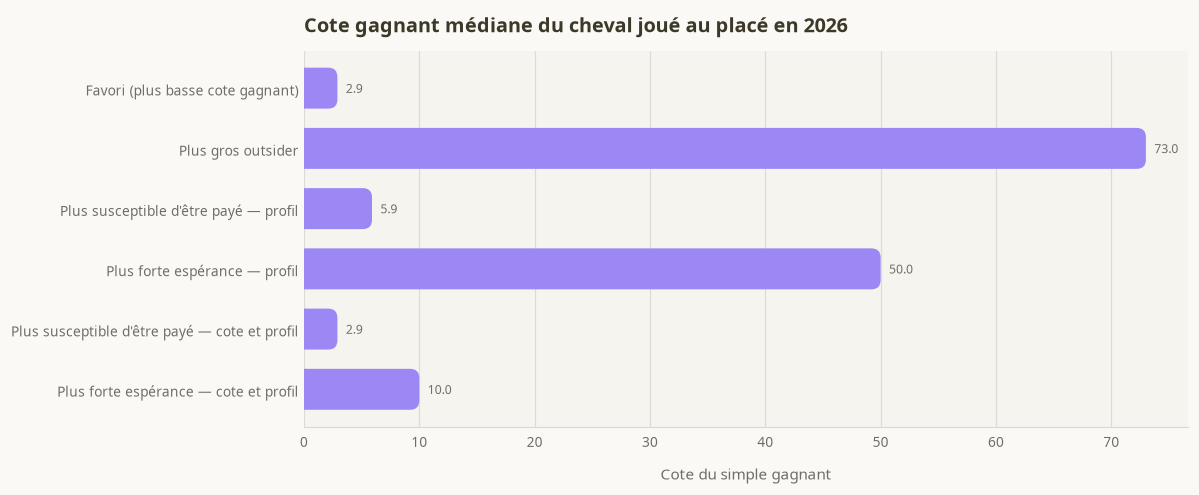

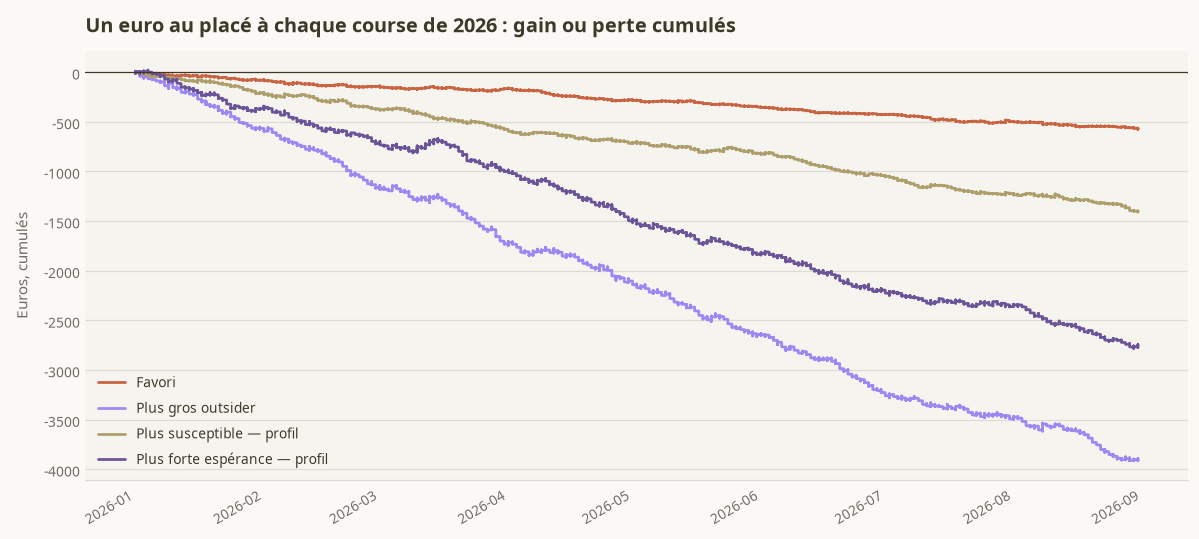

In [9]:
fig, ax = figure("Cote gagnant médiane du cheval joué au placé en 2026", (11, 4.6))
cotes = bilan_modeles["Cote gagnant médiane"]
ax.barh(cotes.index.astype(str)[::-1], cotes.to_numpy()[::-1], color=THEME["chart_2"], height=0.68)
ds.annotate_bars(ax, orientation="horizontal", fmt="{:.1f}")
ds.rounded_bars(ax, orientation="horizontal")
ax.set_xlabel("Cote du simple gagnant")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
fig.tight_layout()


def cumul(choix):
    classe = choix.sort_values(["date_programme", "course_id"])
    flux = classe["retour"].to_numpy(dtype=float) - 1.0
    return classe["date_programme"], np.cumsum(flux)


fig, ax = figure("Un euro au placé à chaque course de 2026 : gain ou perte cumulés", (11, 5))
traces = [
    ("Favori", favori),
    ("Plus gros outsider", gros),
    ("Plus susceptible — profil", une_mise(test, test["p_profil"])),
    ("Plus forte espérance — profil", une_mise(avec_prix, avec_prix["ev_profil"])),
]
for nom, choix in traces:
    dates_courbe, courbe = cumul(choix)
    ax.plot(dates_courbe, courbe, linewidth=1.8, label=nom)
ax.axhline(0, color=THEME["foreground"], linewidth=0.8)
ax.set_ylabel("Euros, cumulés")
ax.legend(frameon=False)
fig.autofmt_xdate()
fig.tight_layout()


**À retenir.** Le profil seul ne voit pas assez la différence entre un favori et un
outsider. En 2026, il prête 37 % de chances d'être payé aux chevaux à moins de 2, qui le
sont dans 78 % des cas, et 21 % aux chevaux à plus de 40, qui le sont dans 6 % des cas.
Multipliées par le dividende moyen appris (10,54 € sur cette dernière tranche), ces chances
fabriquent une espérance de 2,23 € là où 1 € misé n'en rend que 0,67. La règle « plus forte
espérance » choisit alors un cheval de cote 50, rang 9, payé une fois sur dix, pour 0,76 €
rendus.

Le modèle qui voit la cote, quand on lui demande le cheval le plus susceptible d'être payé,
retrouve le favori : 62 % de chevaux payés, 0,95 €. Lui demander l'espérance allonge le prix
jusqu'au 5e rang (cote médiane 10) et rend 0,91 €. On change de cheval. On s'éloigne du seul
rendement qui s'approchait de la mise.


<a id="passer"></a>
## 5. Passer son tour quand le prix n'est pas là

Jusqu'ici, chaque course reçoit une mise. On reprend l'espérance du profil seul, et l'on ne
joue que si le meilleur cheval dépasse un seuil. 1,00 veut dire « le dividende moyen appris,
multiplié par les chances, couvre au moins la mise ». Les seuils sont affichés tous : aucun
n'a été retenu parce qu'il gagnait.


,Paris,Courses jouées,Chevaux payés,Euros rendus pour 1 €,Marge de hasard (±),Cote gagnant médiane,Rang de prix médian
Règle,,,,,,,
"Espérance d'au moins 1,00",11 162,"98,0 %","9,7 %","0,748 €","0,051 €","51,0","9,0"
"Espérance d'au moins 1,05",11 148,"97,9 %","9,7 %","0,749 €","0,051 €","51,0","9,0"
"Espérance d'au moins 1,10",11 037,"96,9 %","9,7 %","0,752 €","0,051 €","51,0","9,0"
"Espérance d'au moins 1,20",10 863,"95,4 %","9,6 %","0,751 €","0,052 €","52,0","9,0"
"Espérance d'au moins 1,40",10 331,"90,7 %","8,9 %","0,735 €","0,053 €","53,0","9,0"


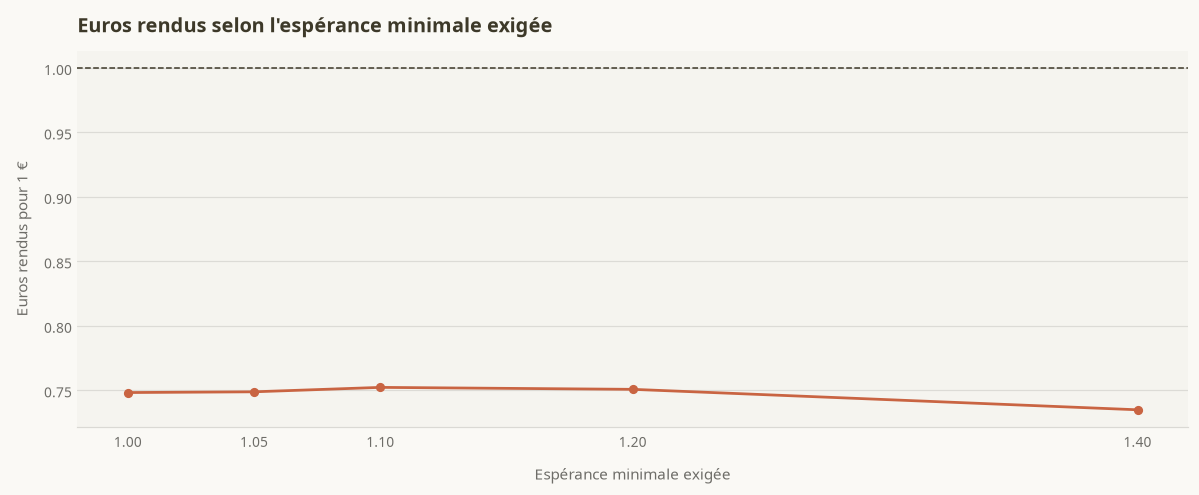

In [10]:
seuils = [1.0, 1.05, 1.1, 1.2, 1.4]
selectif = []
for seuil in seuils:
    meilleur = une_mise(avec_prix, avec_prix["ev_profil"])
    retenu = meilleur[meilleur["_score"] >= seuil]
    selectif.append(decrire(retenu, f"Espérance d'au moins {seuil:.2f}".replace(".", ","), n_test))
bilan_seuils = pd.DataFrame(selectif).set_index("Règle")
display(
    tableau(
        bilan_seuils,
        "2026 : ne jouer au placé que si le profil voit un prix suffisant",
        formats=FORMATS_REGLES,
    )
)

fig, ax = figure("Euros rendus selon l'espérance minimale exigée", (11, 4.6))
ax.plot(
    seuils,
    bilan_seuils["Euros rendus pour 1 €"],
    color=THEME["primary"],
    marker="o",
    linewidth=1.8,
)
ax.axhline(1, color=THEME["foreground"], linewidth=1, linestyle="--")
ax.set_xlabel("Espérance minimale exigée")
ax.set_ylabel("Euros rendus pour 1 €")
ax.set_xticks(seuils)
fig.tight_layout()


**À retenir.** Monter le seuil ne sélectionne pas une affaire. À 1,40, on joue encore 91 %
des courses, autour d'une cote gagnant de 53, pour 0,74 € rendus. Le profil voit un écart
sur presque chaque course, parce qu'il surévalue les outsiders. **L'exigence laisse passer
le prix long, et ce prix long perd plus que le favori.**


<a id="limites"></a>
## 6. Ce qu'il ne faut pas conclure trop vite


In [11]:
limites = pd.DataFrame(
    [
        (
            "Le prix du placé n'est pas connu avant l'arrivée",
            "La cote du gagnant sert à désigner le cheval. Le dividende du rapport ne sert qu'à solder la mise. Un prix de placé affiché avant le départ n'est pas dans cette base.",
        ),
        (
            "Deux places ou trois, selon la course",
            "Finir troisième ne paie pas toujours. Le rapport, pas l'ordre d'arrivée, dit qui a été réglé.",
        ),
        (
            "Le dividende moyen appris est une moyenne",
            "Il ignore que, ce jour-là, le cheval était plus ou moins joué au placé que les chevaux de sa tranche. C'est un prix de substitution, pas le tableau d'affichage.",
        ),
        (
            "Un euro à plat n'est pas une gestion de mise",
            "On ne met pas plus d'argent sur les écarts les plus grands.",
        ),
        (
            "Les chevaux reviennent",
            "Le même nom court des dizaines de fois. Une partie de ce que le modèle reconnaît est une mémoire des habitués.",
        ),
    ],
    columns=["Point de vigilance", "Pourquoi ça compte"],
).set_index("Point de vigilance")
display(
    tableau(
        limites,
        "Avant de prendre le placé pour une chasse aux outsiders",
        formats={"Pourquoi ça compte": "{}"},
    )
)


,Pourquoi ça compte
Point de vigilance,
Le prix du placé n'est pas connu avant l'arrivée,La cote du gagnant sert à désigner le cheval. Le dividende du rapport ne sert qu'à solder la mise. Un prix de placé affiché avant le départ n'est pas dans cette base.
"Deux places ou trois, selon la course","Finir troisième ne paie pas toujours. Le rapport, pas l'ordre d'arrivée, dit qui a été réglé."
Le dividende moyen appris est une moyenne,"Il ignore que, ce jour-là, le cheval était plus ou moins joué au placé que les chevaux de sa tranche. C'est un prix de substitution, pas le tableau d'affichage."
Un euro à plat n'est pas une gestion de mise,On ne met pas plus d'argent sur les écarts les plus grands.
Les chevaux reviennent,Le même nom court des dizaines de fois. Une partie de ce que le modèle reconnaît est une mémoire des habitués.


**À retenir.** Le rapport règle la question de l'argent. Il ne donne pas, à lui seul, un
prix utilisable avant le départ.


<a id="verdict"></a>
## 7. Verdict


In [12]:
verdict = pd.DataFrame(
    [
        (
            "Jouer le favori au placé",
            "Moins mauvais, pas gagnant",
            "Payé dans 62 % des courses, 0,94 € rendus. La marge de hasard (±0,01 €) reste sous la mise.",
        ),
        (
            "Jouer l'outsider au placé",
            "Non",
            "Payé 7 % du temps, dividende plus long, 0,60 € rendus. Le rapport confirme que le prix le plus haut est le plus mauvais achat.",
        ),
        (
            "Descendre dans la cote du gagnant",
            "Non",
            "Du 2e au 6e prix, le rendement baisse de 0,91 € à 0,81 €. Il n'y a pas de rang intermédiaire bénéficiaire.",
        ),
        (
            "Choisir l'espérance plutôt que la place",
            "Le bon geste, si la chance est juste",
            "Sans la cote, l'espérance désigne un cheval de rang 9 et rend 0,76 €. Avec la cote, elle s'arrête au 5e prix et rend 0,91 €, derrière le favori.",
        ),
        (
            "Ne jouer que les écarts les plus nets",
            "Sans effet",
            "Même à 1,40, on joue 91 % des courses de 2026, sur des cotes de 53, pour 0,74 €. Le seuil ne corrige pas une chance trop généreuse pour les outsiders.",
        ),
    ],
    columns=["Question", "Réponse", "Lecture"],
).set_index("Question")
display(
    tableau(
        verdict,
        "Ce que le simple placé change, et ce qu'il ne change pas",
        formats={"Réponse": "{}", "Lecture": "{}"},
    )
)


,Réponse,Lecture
Question,,
Jouer le favori au placé,"Moins mauvais, pas gagnant","Payé dans 62 % des courses, 0,94 € rendus. La marge de hasard (±0,01 €) reste sous la mise."
Jouer l'outsider au placé,Non,"Payé 7 % du temps, dividende plus long, 0,60 € rendus. Le rapport confirme que le prix le plus haut est le plus mauvais achat."
Descendre dans la cote du gagnant,Non,"Du 2e au 6e prix, le rendement baisse de 0,91 € à 0,81 €. Il n'y a pas de rang intermédiaire bénéficiaire."
Choisir l'espérance plutôt que la place,"Le bon geste, si la chance est juste","Sans la cote, l'espérance désigne un cheval de rang 9 et rend 0,76 €. Avec la cote, elle s'arrête au 5e prix et rend 0,91 €, derrière le favori."
Ne jouer que les écarts les plus nets,Sans effet,"Même à 1,40, on joue 91 % des courses de 2026, sur des cotes de 53, pour 0,74 €. Le seuil ne corrige pas une chance trop généreuse pour les outsiders."


Le simple placé paie plus souvent que le gagnant, et les dividendes sont plus courts. Il ne
retourne pas la conclusion. Du 1er janvier 2025 au 31 août 2026, **aucune de ces règles ne
rend la mise**. Le favori reste la moins mauvaise : 0,94 €, et il est payé six fois sur dix.
L'outsider automatique reste la pire : 0,60 €.

Le rapport donne le vrai solde, pas un prix d'avant-course. Tant que la chance estimée ne
baisse pas aussi vite que la cote du gagnant, l'espérance désigne un cheval trop long, et
l'on recrée la règle qui perd le plus. La piste utile n'est pas « jouer le placé sur un
outsider ». C'est une chance d'être payé qui contredit vraiment le prix, avec un prix de
placé connu avant le départ — ce que cette base ne contient pas.
